In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import sawtooth


### a) Construcción de una señal cuadrada periódica


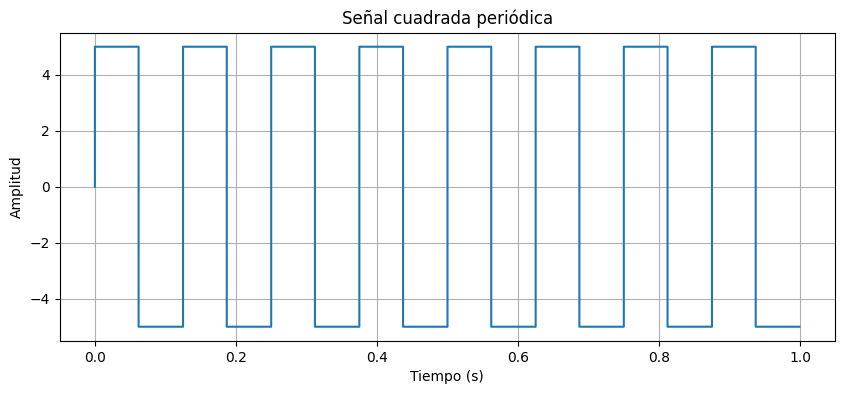

In [5]:

# Parámetros de la señal
f0 = 8          # Frecuencia fundamental en Hz
A = 5          # Amplitud de la señal
N = 1000        # Número de muestras
fs = 1000       # Frecuencia de muestreo en Hz

# Vector de tiempo
t = np.arange(N) / fs

# Construcción de la señal cuadrada
x = A * np.sign(np.sin(2 * np.pi * f0 * t))

# Gráfica de la señal
plt.figure(figsize=(10, 4))
plt.plot(t, x, drawstyle="steps-pre")
plt.title("Señal cuadrada periódica")
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud")
plt.grid(True)
plt.ylim(-A - 0.5, A + 0.5)
plt.show()



### b) Construcción de una señal triangular periódica



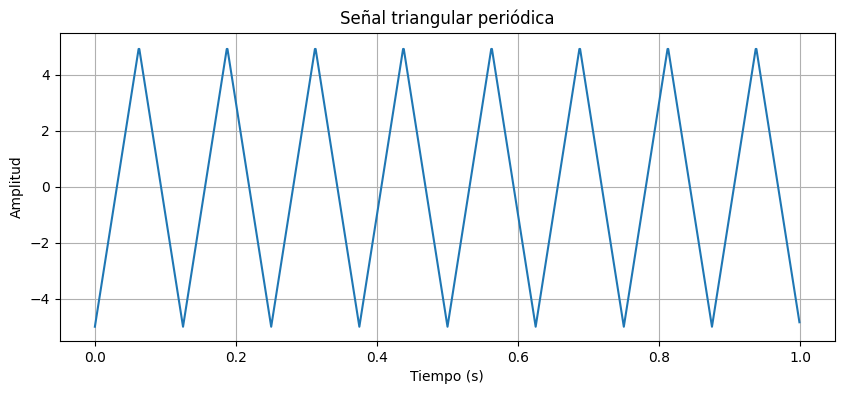

In [14]:

# Parámetros de la señal
f0 = 8       # Frecuencia fundamental en Hz
A = 5       # Amplitud
N = 1000     # Número de muestras
fs = 1000    # Frecuencia de muestreo en Hz

# Vector de tiempo
t = np.arange(N) / fs

# Construcción de la señal triangular
x_triangular = A * sawtooth(2 * np.pi * f0 * t, width=0.5)

# Gráfica de la señal triangular
plt.figure(figsize=(10, 4))
plt.plot(t, x_triangular)
plt.title("Señal triangular periódica")
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud")
plt.ylim(-A - 0.5, A + 0.5)
plt.grid(True)
plt.show()



### c) Gráfica de ambas señales en el dominio del tiempo

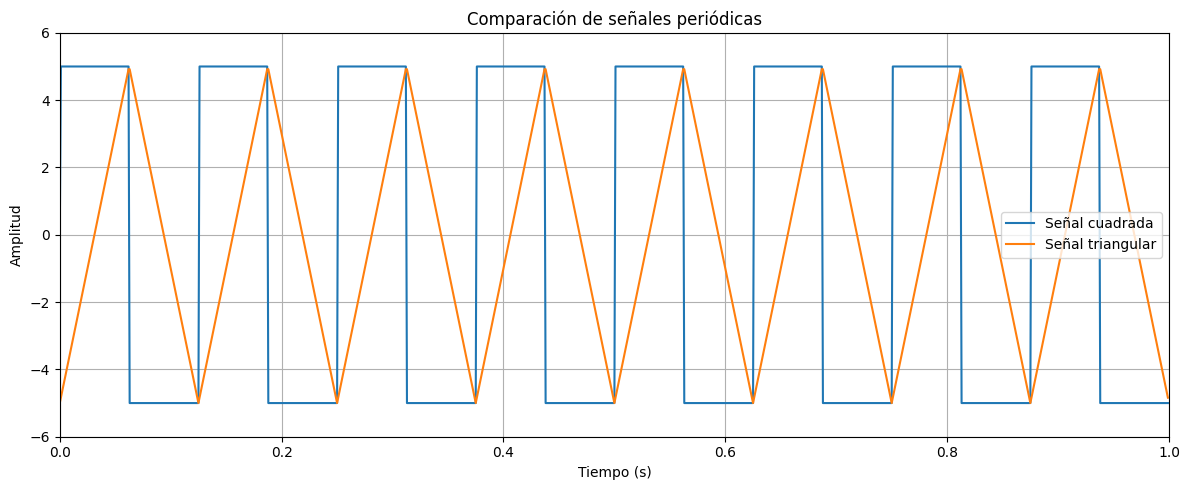

In [15]:

# Gráfica comparativa de las señales existentes

plt.figure(figsize=(12, 5))

plt.plot(t, x, label="Señal cuadrada")
plt.plot(t, x_triangular, label="Señal triangular")

plt.title("Comparación de señales periódicas")
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud")
plt.xlim(0, 1)
plt.ylim(-6, 6)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()



### d) Cálculo de los coeficientes de la serie exponencial de Fourier

Se implementó una función que recibe una señal periódica y calcula sus coeficientes de la serie exponencial de Fourier mediante NumPy, utilizando la transformada discreta de Fourier normalizada.

Los coeficientes se calculan mediante la expresión:

$$C_k = \frac{1}{N}\sum_{n=0}^{N-1} x[n]e^{-j\frac{2\pi kn}{N}}$$

donde **x[n]** representa las muestras de un periodo de la señal, **N** es el número de muestras por periodo y **k** es el índice armónico.

La función se aplicó a las señales cuadrada y triangular construidas previamente, seleccionando un periodo completo de cada una para obtener sus respectivos coeficientes.


In [11]:
def coeficientes_fourier(x_periodo):
    """
    Calcula los coeficientes exponenciales de Fourier
    de un periodo de una señal periódica.

    Parámetro:
        x_periodo: muestras de un periodo completo.

    Retorna:
        k: índices armónicos.
        Ck: coeficientes complejos de Fourier.
    """
    x_periodo = np.asarray(x_periodo)
    N = len(x_periodo)

    # Transformada discreta de Fourier normalizada
    Ck = np.fft.fft(x_periodo) / N

    # Índices armónicos centrados en cero
    Ck = np.fft.fftshift(Ck)
    k = np.fft.fftshift(np.fft.fftfreq(N, d=1/N))

    return k, Ck


# Seleccionar un periodo completo de cada señal
muestras_periodo = int(fs / f0)

x_cuadrada_periodo = x[:muestras_periodo]
x_triangular_periodo = x_triangular[:muestras_periodo]

# Calcular coeficientes de Fourier
k_cuadrada, Ck_cuadrada = coeficientes_fourier(
    x_cuadrada_periodo
)

k_triangular, Ck_triangular = coeficientes_fourier(
    x_triangular_periodo
)

# Mostrar algunos coeficientes de cada señal
print("Coeficientes de Fourier de la señal cuadrada:")
for i in range(10):
    print(f"k = {k_cuadrada[i]:4.0f}, "
          f"Ck = {Ck_cuadrada[i]:.4f}")

print("\nCoeficientes de Fourier de la señal triangular:")
for i in range(10):
    print(f"k = {k_triangular[i]:4.0f}, "
          f"Ck = {Ck_triangular[i]:.4f}")


Coeficientes de Fourier de la señal cuadrada:
k = -100, Ck = 0.0250+0.0000j
k =  -99, Ck = -0.0501-0.0143j
k =  -98, Ck = -0.0362-0.0242j
k =  -97, Ck = 0.0321+0.0045j
k =  -96, Ck = -0.0250-0.0470j
k =  -95, Ck = 0.0027-0.0307j
k =  -94, Ck = 0.0379+0.0274j
k =  -93, Ck = 0.0132-0.0458j
k =  -92, Ck = 0.0250+0.0000j
k =  -91, Ck = 0.0178+0.0567j

Coeficientes de Fourier de la señal triangular:
k = -100, Ck = 0.0000-0.0000j
k =  -99, Ck = -0.0002-0.0000j
k =  -98, Ck = 0.0000+0.0000j
k =  -97, Ck = -0.0002+0.0000j
k =  -96, Ck = 0.0000+0.0000j
k =  -95, Ck = -0.0002-0.0000j
k =  -94, Ck = 0.0000-0.0000j
k =  -93, Ck = -0.0002-0.0000j
k =  -92, Ck = 0.0000+0.0000j
k =  -91, Ck = -0.0002+0.0000j
